# 2D patch generation on a synthetic slice

This small example is entirely synthetic. Its image, ventricular mask, affine
and point annotation were generated without using patient data. The dark cavity
and bright rim only illustrate a lacune-like object.

Install the package and optional notebook dependencies from the repository root:
`python -m pip install -e ".[notebook]"`, then open this notebook in JupyterLab.
Run cells in order with the kernel working directory set to `examples/`.
All paths below are relative; no external dataset is required.

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
import h5py
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from louisa_patch_generation import PatchGenerator

plt.rcParams.update({"font.size": 11, "figure.facecolor": "white", "axes.facecolor": "white"})

## Load the included data

A 2D slice is represented as a 3D image with shape `(128, 128, 1)`.
The point uses zero-based voxel indices `[i, j, k]`. ID `1` identifies the
synthetic object and will repeat across patches that qualify as positive.

In [ ]:
with np.load(Path("data") / "synthetic_slice.npz") as data:
    images = {
        name: nib.Nifti1Image(data[name], data["affine"])
        for name in ("FLAIR", "ventricles")
    }
    annotations = data["annotations"].copy()
    annotations_ids = data["annotations_ids"].copy()
for image in images.values():
    image.header.set_xyzt_units("mm")

pg = PatchGenerator(images, 
                    mask_names="ventricles", 
                    annotations=annotations,
                    annotations_ids=annotations_ids)

print("Input shapes:", {name: image.shape for name, image in images.items()})
print("Point coordinates:", annotations)
print("Point IDs:", annotations_ids)

Input shapes: {'FLAIR': (128, 128, 1), 'ventricles': (128, 128, 1)}
Point coordinates: [[70. 80.  0.]]
Point IDs: [1]


## Preprocess and generate patches

The input already has 1 mm spacing, so preprocessing leaves its geometry
unchanged. `slice_axis=2` selects the single slice; outputs have shape
`(N, side, side)`. Sizes 32 and 48 share centers, with no padding. A positive
label requires a point at least 5 voxels inward from the patch boundary.

In [3]:
prepared, points = pg.preprocess(target_spacing=(1, 1, 1))
patches = pg.generate_patches(mode="2d", patch_sizes=(32, 48), stride=12,
                              label_border=5, slice_axis=2, generator=False)
for size in (32, 48):
    print(f"FLAIR {size}: {patches['FLAIR'][size].shape}; positive labels: {int(patches['label'][size].sum())}")
print("Shared coordinates:", patches["coordinates"].shape)

FLAIR 32: (49, 32, 32); positive labels: 4
FLAIR 48: (49, 48, 48); positive labels: 9
Shared coordinates: (49, 3)


## View the slice and paired windows

The marker is the annotated synthetic object. The two squares show a shared
center for the 32- and 48-voxel windows. Axes follow array coordinates: `i`
is horizontal and `j` is vertical, using `.T` for display.

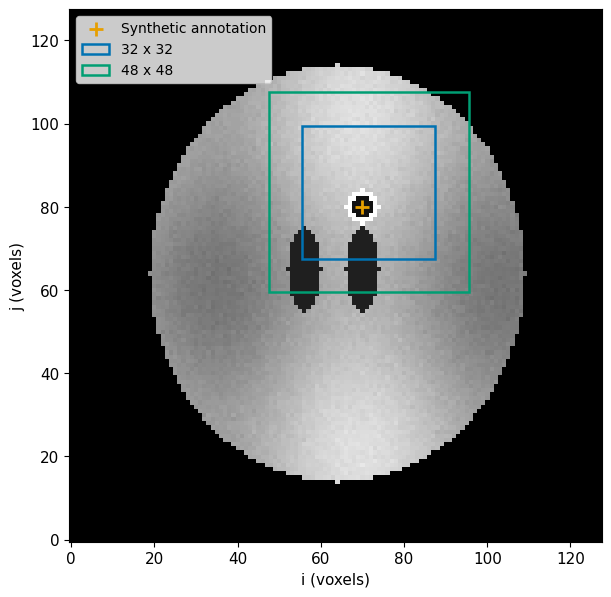

In [ ]:
coordinates = patches["coordinates"]
positive_rows = np.flatnonzero((patches["label"][32] == 1) & (patches["label"][48] == 1))
positive_index = positive_rows[np.argmin(np.linalg.norm(coordinates[positive_rows, :2] - points[0, :2], axis=1))]
source_image = np.asarray(prepared["FLAIR"].dataobj)[:, :, 0]
maximum_intensity = float(source_image.max())


fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
ax.imshow(source_image.T, origin="lower", cmap="gray", vmin=0, vmax=maximum_intensity)
ax.scatter(points[:, 0], points[:, 1], marker="+", s=100, linewidths=2,
           color="#e69f00", label="Synthetic annotation")
for size, color in ((32, "#0072b2"), (48, "#009e73")):
    start = coordinates[positive_index, :2] - (size - 1) / 2
    ax.add_patch(Rectangle(start - 0.5, size, size, fill=False, linewidth=1.8,
                           edgecolor=color, label=f"{size} x {size}"))
ax.set_xlabel("i (voxels)")
ax.set_ylabel("j (voxels)")
ax.legend(loc="upper left", fontsize=10)
plt.show()

## Compare extracted patches

Each column shows the same position at both sizes: a positive patch near the
annotation, a patch without the object, and a patch with much background.
ID `[0]` means no point meets the label criterion. A patch may contain part of
the object yet have label 0 when its point fails `label_border`.

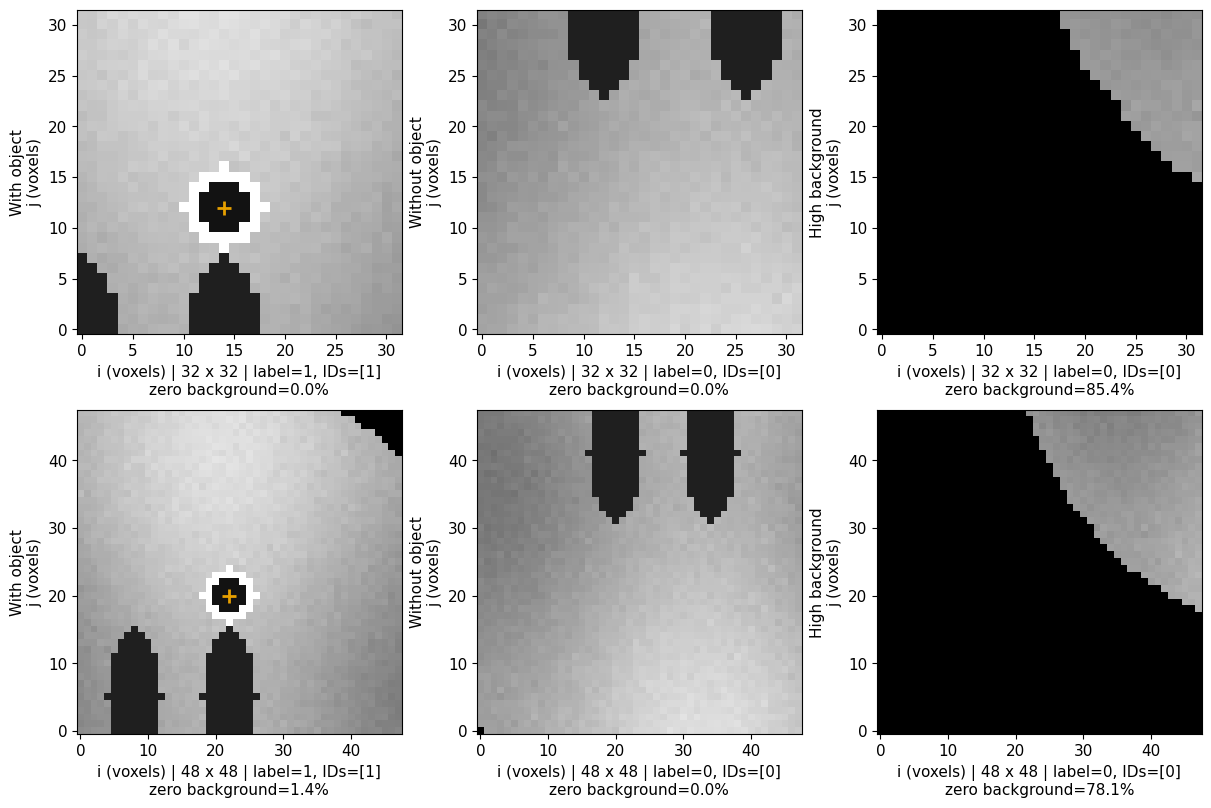

In [ ]:
background = {
    size: 100.0 * np.count_nonzero(patches["FLAIR"][size] == 0, axis=(1, 2)) / size ** 2
    for size in (32, 48)
}

distance = np.max(np.abs(coordinates[:, :2] - points[0, :2]), axis=1)
negative_rows = np.flatnonzero((distance >= 24) & (background[48] < 75))
negative_index = negative_rows[np.argmin(background[48][negative_rows])]
background_index = int(np.argmax(background[48]))

examples = [("With object", int(positive_index)), 
            ("Without object", int(negative_index)),
            ("High background", background_index)]


fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")
for row, size in enumerate((32, 48)):
    for column, (description, index) in enumerate(examples):
        ax = axes[row, column]
        ax.imshow(patches["FLAIR"][size][index].T, origin="lower", cmap="gray",
                  vmin=0, vmax=maximum_intensity)
        start = coordinates[index, :2] - (size - 1) / 2
        local_points = points[:, :2] - start
        inside = np.all((local_points >= -0.5) & (local_points < size - 0.5), axis=1)
        ax.scatter(local_points[inside, 0], local_points[inside, 1], marker="+",
                   s=90, linewidths=2, color="#e69f00")
        label = int(patches["label"][size][index])
        ids = patches["annotations_ids"][size][index].tolist()
        ax.set_xlabel(f"i (voxels) | {size} x {size} | label={label}, IDs={ids}\n"
                      f"zero background={background[size][index]:.1f}%")
        ax.set_ylabel(f"{description}\nj (voxels)")
plt.show()

## Filter synchronized positions

Any position with more than 75% exact-zero FLAIR background in either size is
removed; equality at the threshold is accepted. `remove_inconsistent=True`
also removes positions whose binary labels differ between sizes. Images,
masks, centers, labels and ID lists always remain aligned.

In [ ]:
filtered = pg.postprocess(max_zero_percent=75, 
                          remove_inconsistent=True, 
                          reference="FLAIR")

print("Retained positions:", len(filtered["coordinates"]), "/", len(patches["coordinates"]))

for size in (32, 48):
    print(f"Size {size}: shape={filtered['FLAIR'][size].shape}; positive labels={int(filtered['label'][size].sum())}")

positive = np.flatnonzero(filtered["label"][32] == 1)
print("IDs of positive 32-voxel patches:", [filtered["annotations_ids"][32][i].tolist() for i in positive])

Retained positions: 43 / 49
Size 32: shape=(43, 32, 32); positive labels=4
Size 48: shape=(43, 48, 48); positive labels=4
IDs of positive 32-voxel patches: [[1], [1], [1], [1]]


## Save and read HDF5

This round trip uses a temporary directory so the notebook can be run repeatedly.
To keep a result, call `pg.save_hdf5("your_new_filename.h5")` instead. Existing
files are refused. Point IDs and per-patch ID lists are stored separately.

In [ ]:
with TemporaryDirectory() as output_directory:
    pg.save_hdf5(Path(output_directory) / "synthetic_patches.h5")
    
    with h5py.File(Path(output_directory) / "synthetic_patches.h5", "r") as saved:
        print("Saved FLAIR 32 shape:", saved["images/FLAIR/32"].shape)
        print("Source point IDs:", saved["annotations_ids"][:])
        row = int(positive[0])
        print("One positive patch ID list:", saved["patch_annotations_ids/32"][row])
        print("Complete:", bool(saved.attrs["complete"]))

Saved FLAIR 32 shape: (43, 32, 32)
Source point IDs: [1]
One positive patch ID list: [1]
Complete: True
